# Step 0. Setup

Install needed requirements:
```bash
pip install -r requirements.txt
pip install soliday.sdds
```

Create `content` directory, where you will download environment setup.
```bash
mkdir content
```

You need to install and put it in the `content` folder:
- RPN definitions(`defns.rpn);
- SDDS;
- Elegant.

```bash
# RPN definitions
wget -q https://ops.aps.anl.gov/downloads/defns.rpn -O ./content/defns.rpn
# SDDS toolkit 
python3 -m gdown 19v2TnS-MKXjVrvmRp09bF2z9JK4oDQAu -O ./content/
sudo apt-get install -y ./content/sddstoolkit_5.8-2_amd64.deb
# Elegant toolkit
python3 -m gdown 1HvEKVeq6Cwsrj13mKguLmt8z_fDWxMY7 -O ./content/
sudo apt-get install -y ./content/elegant_2025.2.0-2_amd64.deb
```

In [33]:
import os
import shutil
import logging

from pathlib import Path

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(name)s - %(levelname)s - %(message)s'
)
logger = logging.getLogger("callibration.ipynb")

# Needed setup
rpn_path = Path("./content/defns.rpn")
if not rpn_path.exists():
    logger.error(f"RPN definitions not found: {rpn_path}")

os.environ["RPN_DEFNS"] = str(rpn_path)
os.environ["HOST_ARCH"] = "linux-x86_64"
os.environ["EPICS_HOST_ARCH"] = "linux-x86_64"

# Required binaries check
req_bins = {"elegant", "sdds2stream", "sddsquery", "sddsprocess"}
for binary in req_bins:
    if not shutil.which(binary):
        logger.error(f"{binary=} not found!")

# Step 1. Setup input parameters

You should insert `machine_info`, `track_info` and `config.json` as input params.

In [87]:
machine_info = Path("machine_3b.lte")
track_info = Path("track_3b.ele")
config_json = Path("config_3b.json")
config_noisy_json = Path("config_3b_noisy.json")

if not machine_info.exists():
    logger.error(f"{machine_info=} doesn't exist")
if not track_info.exists():
    logger.error(f"{track_info=} doesn't exist")
if not config_json.exists():
    logger.error(f"{config_json=} doesn't exist")
if not config_noisy_json.exists():
    logger.error(f"{config_json=} doesn't exist")

Setup check, need to verify that your input `.json`, `.lte`, `.ele` files are compatible.

In [88]:
import subprocess

setup_check = subprocess.run(
    [
        "python3", "train.py",
        "--config", config_json,
        "--check-setup",
    ],
    cwd=Path("../"),
    text=True,
)

2026-11-06 16:37:38,260 - __main__ - INFO - ================================================================================
2026-11-06 16:37:38,261 - __main__ - INFO - ENVIRONMENT INFORMATION
2026-11-06 16:37:38,261 - __main__ - INFO - ================================================================================
2026-11-06 16:37:38,261 - __main__ - INFO - Python Version: 3.10.19 (main, Feb 12 2026, 00:42:18) [Clang 21.1.4 ]
2026-11-06 16:37:38,261 - __main__ - INFO - Python Executable: /home/alex/study_stuff/RL-ABC/.venv/bin/python3
2026-11-06 16:37:38,261 - __main__ - INFO - Working Directory: /home/alex/study_stuff/RL-ABC
2026-11-06 16:37:38,261 - __main__ - INFO - ================================================================================
2026-11-06 16:37:38,261 - __main__ - INFO - Loading configuration from: config_3b.json
2026-11-06 16:37:38,261 - __main__ - INFO - Using CPU
2026-11-06 16:37:38,262 - __main__ - INFO - RL-ABC setup check passed
2026-11-06 16:37:38,263 - __

Smoke test run, need to verify `RL-ABC`, `Elegant` and `SDDS` communication

In [92]:
seed_num = 0x3b
noisy_seed_num = 0x3bbb

In [94]:
# defined by training scripts
output_log_fld = Path("..") / Path(f"logs_{seed_num}")
output_results_fld = Path("..") / Path(f"quickstart_results_{seed_num}")
output_noisy_log_fld = Path("..") / Path(f"logs_{noisy_seed_num}")
output_noisy_results_fld = Path("..") / Path(f"quickstart_results_{noisy_seed_num}")


res_paths = [output_log_fld, output_results_fld, output_noisy_log_fld, output_noisy_results_fld]
for pth in res_paths:
    if pth.exists():
        # TODO: maybe backup should be applied instead of erasure
        print(f"Erasing folder {pth} with previous results")
        shutil.rmtree(pth)

In [101]:
init_num_particles = 100
training_episodes = 200

In [102]:
subprocess.run(
    [
        "python3", "train.py",
        "--config", config_json,
        "--training.seed", str(seed_num),
        "--training.n_episodes", str(training_episodes),
        "--environment.init_num_particles", str(init_num_particles),
    ],
    cwd=Path("../"),
    text=True,
)
print(f"Output stored into {output_log_fld}/, {output_results_fld}/")

2026-11-06 16:45:36,674 - __main__ - INFO - ================================================================================
2026-11-06 16:45:36,675 - __main__ - INFO - ENVIRONMENT INFORMATION
2026-11-06 16:45:36,675 - __main__ - INFO - ================================================================================
2026-11-06 16:45:36,675 - __main__ - INFO - Python Version: 3.10.19 (main, Feb 12 2026, 00:42:18) [Clang 21.1.4 ]
2026-11-06 16:45:36,675 - __main__ - INFO - Python Executable: /home/alex/study_stuff/RL-ABC/.venv/bin/python3
2026-11-06 16:45:36,675 - __main__ - INFO - Working Directory: /home/alex/study_stuff/RL-ABC
2026-11-06 16:45:36,675 - __main__ - INFO - ================================================================================
2026-11-06 16:45:36,675 - __main__ - INFO - Loading configuration from: config_3b.json
2026-11-06 16:45:36,676 - __main__ - INFO - Using CPU
2026-11-06 16:45:36,680 - __main__ - INFO - Reproducibility seed set to: 59
2026-11-06 16:45:36,68

Seed set to: 59
Updated lattice filename in track_3b_59.ele to: machine_3b.lte


2026-11-06 16:45:40,668 - rl_framework.Environment - INFO - Training initial particles: 100 (generated bunched_beam)


Training initial particles: 100 (generated bunched_beam)


2026-11-06 16:45:41,080 - __main__ - INFO - Environment setup completed
2026-11-06 16:45:41,080 - __main__ - INFO - Setting up agent...
2026-11-06 16:45:41.903422: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-06 16:45:42.005102: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-06 16:45:42.005213: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-06 16:45:42.007490: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to registe

Seed set to: 59


... (2 outputs left out)

2026-11-06 16:57:27,464 - __main__ - INFO - Training completed
2026-11-06 16:57:27,528 - __main__ - INFO - Saved replay buffer to quickstart_fodo_buffer_59.pkl
2026-11-06 16:57:27,528 - __main__ - INFO - Evaluating agent for 1 episode(s)...


Episode: 1
rewards: 0.004556962025316456
DDPG Models saved successfully (last) at step 2352.
DDPG Evaluation completed at step 2352
Evaluation log kept at: logs_59/run_20261106_164548_438768_pid91679/ddpg_eval_episode_0200_step_0002352_eval_041.csv
Average reward: 10.13 over 1 episodes
Best number_of_particles so far: 29
@@@@@@@ DONE DDPG EVALUATING @@@@@@@


2026-11-06 16:57:30,972 - __main__ - INFO - Evaluation completed
2026-11-06 16:57:30,972 - __main__ - INFO - Training workflow completed successfully!


Output stored into ../logs_59/, ../quickstart_results_59/


In [103]:
subprocess.run(
    [
        "python3", "train.py",
        "--config", config_noisy_json,
        "--training.seed", str(seed_num),
        "--training.n_episodes", str(training_episodes),
        "--environment.init_num_particles", str(init_num_particles),
    ],
    cwd=Path("../"),
    text=True,
)
print(f"Output stored into {output_noisy_log_fld}/, {output_noisy_results_fld}/")

2026-11-06 16:57:38,397 - __main__ - INFO - ================================================================================
2026-11-06 16:57:38,398 - __main__ - INFO - ENVIRONMENT INFORMATION
2026-11-06 16:57:38,398 - __main__ - INFO - ================================================================================
2026-11-06 16:57:38,398 - __main__ - INFO - Python Version: 3.10.19 (main, Feb 12 2026, 00:42:18) [Clang 21.1.4 ]
2026-11-06 16:57:38,398 - __main__ - INFO - Python Executable: /home/alex/study_stuff/RL-ABC/.venv/bin/python3
2026-11-06 16:57:38,398 - __main__ - INFO - Working Directory: /home/alex/study_stuff/RL-ABC
2026-11-06 16:57:38,398 - __main__ - INFO - ================================================================================
2026-11-06 16:57:38,398 - __main__ - INFO - Loading configuration from: config_3b_noisy.json
2026-11-06 16:57:38,399 - __main__ - INFO - Using CPU
2026-11-06 16:57:38,403 - __main__ - INFO - Reproducibility seed set to: 59
2026-11-06 16:57

Seed set to: 59
Updated lattice filename in track_3b_59.ele to: machine_3b.lte
Training initial particles: 100 (generated bunched_beam)


2026-11-06 16:57:42,322 - rl_framework.Environment - INFO - Training initial particles: 100 (generated bunched_beam)
2026-11-06 16:57:42,753 - __main__ - INFO - Environment setup completed
2026-11-06 16:57:42,753 - __main__ - INFO - Setting up agent...
2026-11-06 16:57:43.530587: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-06 16:57:43.630880: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-06 16:57:43.631005: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-06 16:57:43.633120: E ex

Seed set to: 59


2026-11-06 16:57:51,091 - __main__ - INFO - Agent setup completed
2026-11-06 16:57:51,092 - __main__ - INFO - Starting training for 200 episodes...


Step 20: Critic loss 0.1006, Actor loss -0.7504
Step 40: Critic loss 0.0579, Actor loss -0.7430
Step 60: Critic loss 0.0505, Actor loss -0.8406
####### DDPG EVALUATING #########
Episode: 1
rewards: -0.8326500884694864
DDPG Models saved successfully (best) at step 61.
New best model! number_of_particles: 1 at step 61
DDPG Models saved successfully (last) at step 61.
DDPG Evaluation completed at step 61
Evaluation log kept at: logs_59/run_20261106_165751_091558_pid101661/ddpg_eval_episode_0005_step_0000061_eval_001.csv
Average reward: 1.13 over 1 episodes
Best number_of_particles so far: 1
@@@@@@@ DONE DDPG EVALUATING @@@@@@@
Step 80: Critic loss 0.0848, Actor loss -0.8343
####### DDPG EVALUATING #########
Episode: 1
rewards: -0.8571201995900612
DDPG Models saved successfully (best) at step 100.
New best model! number_of_particles: 3 at step 100
DDPG Models saved successfully (last) at step 100.
DDPG Evaluation completed at step 100
Evaluation log kept at: logs_59/run_20261106_165751_091

2026-11-06 17:09:44,670 - __main__ - INFO - Training completed
2026-11-06 17:09:44,718 - __main__ - INFO - Saved replay buffer to quickstart_fodo_buffer_59.pkl
2026-11-06 17:09:44,718 - __main__ - INFO - Evaluating agent for 1 episode(s)...


Episode: 1
rewards: 0.027258064516129034
DDPG Models saved successfully (last) at step 2378.
DDPG Evaluation completed at step 2378
Evaluation log kept at: logs_59/run_20261106_165751_091558_pid101661/ddpg_eval_episode_0200_step_0002378_eval_041.csv
Average reward: 8.92 over 1 episodes
Best number_of_particles so far: 45
@@@@@@@ DONE DDPG EVALUATING @@@@@@@


2026-11-06 17:09:47,793 - __main__ - INFO - Evaluation completed
2026-11-06 17:09:47,793 - __main__ - INFO - Training workflow completed successfully!


Output stored into ../logs_15291/, ../quickstart_results_15291/


,training_steps,final_particles,transmission_percent,episode_return
0,1,0,0.0,5.645334
1,1,0,0.0,5.678617
2,1,0,0.0,5.678617
3,1,0,0.0,5.645334
4,1,0,0.0,5.678617
...,...,...,...,...
82,39,18,18.0,8.604741
83,40,6,6.0,10.129843
84,40,26,26.0,8.998404
85,41,6,6.0,10.129843


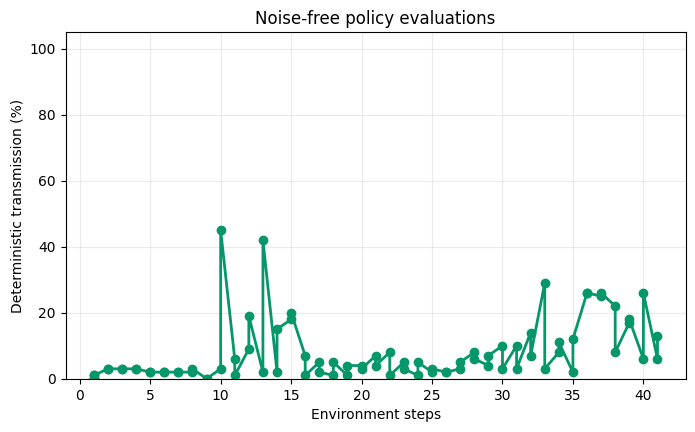

In [104]:
import pandas as pd
import matplotlib.pyplot as plt

evaluation_rows = []
for path in sorted(
    output_log_fld.rglob("ddpg_eval_*.csv"),
    key=lambda p: int(p.stem.split("_")[-1]),
):
    frame = pd.read_csv(path)
    if frame.empty:
        continue
    final_row = frame.iloc[-1]
    evaluation_rows.append({
        "training_steps": int(path.stem.split("_")[-1]),
        "final_particles": int(final_row["number_of_particles"]),
        "episode_return": float(final_row["episode_reward"]),
        "actions": final_row["actions"],
    })

evaluation_df = pd.DataFrame(evaluation_rows)
if evaluation_df.empty:
    print("No evaluation files were found.")
else:
    evaluation_df["transmission_percent"] = (
        100 * evaluation_df["final_particles"] / init_num_particles
    )
    display(evaluation_df[
        [
            "training_steps", "final_particles",
            "transmission_percent", "episode_return",
        ]
    ])

    plt.figure(figsize=(8, 4.5))
    plt.plot(
        evaluation_df["training_steps"],
        evaluation_df["transmission_percent"],
        "o-", color="#059669", linewidth=2,
    )
    plt.ylim(0, 105)
    plt.xlabel("Environment steps")
    plt.ylabel("Deterministic transmission (%)")
    plt.title("Noise-free policy evaluations")
    plt.grid(alpha=0.25)
    plt.show()


In [105]:
import pandas as pd
import matplotlib.pyplot as plt

evaluation_rows = []
for path in sorted(
    output_noisy_log_fld.rglob("ddpg_eval_*.csv"),
    key=lambda p: int(p.stem.split("_")[-1]),
):
    frame = pd.read_csv(path)
    if frame.empty:
        continue
    final_row = frame.iloc[-1]
    evaluation_rows.append({
        "training_steps": int(path.stem.split("_")[-1]),
        "final_particles": int(final_row["number_of_particles"]),
        "episode_return": float(final_row["episode_reward"]),
        "actions": final_row["actions"],
    })

evaluation_df = pd.DataFrame(evaluation_rows)
if evaluation_df.empty:
    print("No evaluation files were found.")
else:
    evaluation_df["transmission_percent"] = (
        100 * evaluation_df["final_particles"] / init_num_particles
    )
    display(evaluation_df[
        [
            "training_steps", "final_particles",
            "transmission_percent", "episode_return",
        ]
    ])

    plt.figure(figsize=(8, 4.5))
    plt.plot(
        evaluation_df["training_steps"],
        evaluation_df["transmission_percent"],
        "o-", color="#059669", linewidth=2,
    )
    plt.ylim(0, 105)
    plt.xlabel("Environment steps")
    plt.ylabel("Deterministic transmission (%)")
    plt.title("Noise-free policy evaluations")
    plt.grid(alpha=0.25)
    plt.show()


No evaluation files were found.
